# CIFAR10 additive normalizing-flow geometry experiment

Adapted from `mnist_additive_nflow.ipynb`. Run in the same project environment with the original `src` package, PyTorch, torchvision, nflows, NumPy, Pillow, matplotlib, and tqdm. These notebooks have not been executed against your project implementation.

## Preserved experiments
- Same parity-convolution/tanh flow, standard-normal base, L=128, K=5, order=6, six flows, Adam learning rate 0.001, and 100 epochs.
- Seed 31 and 80/20 split; no augmentation or dequantization (matching the original experiment).
- Sampling; pullback geodesics and barycentre; rank-20 tangent-space PGA; isometrized geodesics and PGA with five intervals; Euclidean geodesics and PCA; relative RMSE and scatter comparisons.
- The source's shared pullback barycentre is deliberately retained as the base point for all three low-rank solvers, including Euclidean PCA. This is not recentered Euclidean PCA.

## Dataset-specific changes and execution
- Input is 3 x 32 x 32; normalization is fixed channelwise mean/std 0.5, i.e. pixel values map to [-1, 1]. Inverse normalization and clipping apply only to plots, never calculations.
- Training defaults to enabled. `resume_training=True` resumes a local last checkpoint; the best training-NLL checkpoint is loaded for analysis. Checkpoints now store correctly updated best loss and sample-weighted epoch NLL.
- All results go to a dataset-specific directory. Existing source outputs are removed.
- CIFAR-10 downloads through torchvision. The official training partition is split 80/20 as in the source; the official test set is not used. Training and analysis batch sizes are both 128.

The original custom image classes must support three channels. Only the notebook was supplied; their implementation and numerical behavior cannot be verified here.


In [1]:
import os
import glob
import numpy as np
import torch
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
import torchvision
import matplotlib.pyplot as plt
from nflows import flows, transforms, distributions
from nflows.transforms.normalization import ActNorm
from tqdm import tqdm

from src.diffeomorphisms.image.nflow import NFlowImageDiffeomorphism
from src.dimension_reduction.principal_geodesic_analysis.image.l2_tangent_space_pca import l2TangentSpacePCAImageSolver
from src.manifolds.euclidean.image.pullback.standard import StandardPullbackImageEuclidean
from src.manifolds.euclidean.image.standard import StandardImageEuclidean
from src.manifolds.isometrized_euclidean.image import l2IsometrizedImageEuclidean
from src.transforms.multi_layer_parity_conv2d.tanh import MultiLayerTanhParityConv2DTransform
from src.transforms.parity_conv import ParityConv2DTransform

device = "cuda" if torch.cuda.is_available() else "cpu"

# Set random seed for reproducibility
seed = 31
torch.manual_seed(seed)
np.random.seed(seed)

# Experiment settings
size = 32
C = 3
results_folder = os.path.join("results",f"cifar10_{size}x{size}","additive-tanh-isotropic-nflow-pullback")
train_model = True
resume_training = True

plt.rcParams['font.size'] = 20  # Change this value to your desired font size
os.makedirs(results_folder, exist_ok=True)


/Users/wdiepeveen/Documents/Postdoc/projects/2 - Riemannian geometry-based fairness in data science/src/iso-Riemannian-geometry/src/dimension_reduction/principal_geodesic_analysis/__init__.py:6: SyntaxWarning: invalid escape sequence '\i'
  """ Implements base class for solving the PGA problem of finding some rank-r matrix Xi_x \in R^{n x d_1 x ... x d_n} such that \|Y - exp_x(Xi_x)\|_F^2 is small """


### Learning Geometry ###

100%|██████████| 170M/170M [19:10<00:00, 148kB/s]     


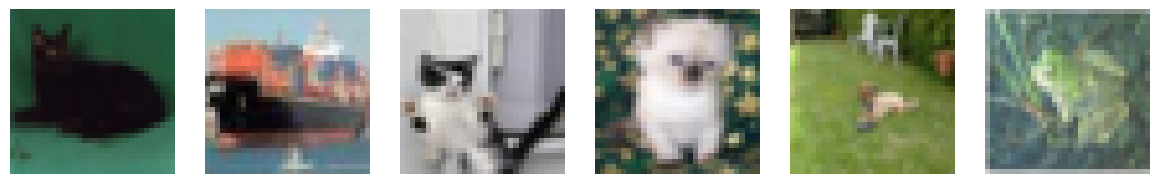

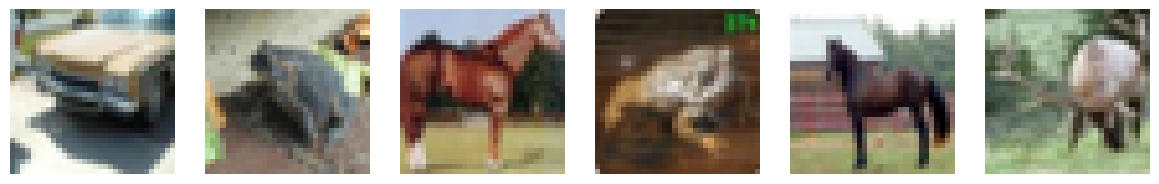

In [2]:
H, W = size, size
# Fixed affine normalization: same convention for both RGB datasets.
image_mean = (0.5, 0.5, 0.5)
image_std = (0.5, 0.5, 0.5)
transform = torchvision.transforms.Compose([
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize(image_mean, image_std),
])
full_dataset = torchvision.datasets.CIFAR10(
    root='./data', train=True, download=True, transform=transform)
batch_size = 128
analysis_batch_size = 128
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
if train_size == 0 or val_size < analysis_batch_size:
    raise ValueError('Dataset too small for the configured split and analysis sample.')
data_train, data_val = random_split(full_dataset, [train_size, val_size],
    generator=torch.Generator().manual_seed(seed))
train_loader = DataLoader(data_train, batch_size=batch_size, shuffle=False, num_workers=0)
val_loader = DataLoader(data_val, batch_size=analysis_batch_size, shuffle=False, num_workers=0)
train_images, _ = next(iter(train_loader))
val_images, val_labels = next(iter(val_loader))

# Display only: all calculations use unclipped, normalized RGB tensors.
def display_image(image):
    image = torch.as_tensor(image).detach().cpu().reshape(C, H, W)
    mean = torch.tensor(image_mean).view(C, 1, 1)
    std = torch.tensor(image_std).view(C, 1, 1)
    return (image * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

for images in (train_images, val_images):
    fig, axes = plt.subplots(1, 6, figsize=(12, 3))
    for i, ax in enumerate(axes):
        ax.imshow(display_image(images[i]))
        ax.axis('off')
    plt.tight_layout()
    plt.show()


In [3]:
# Define the normalizing flow model
def create_flow_model(in_channels, height, width, kernel_size, latent_channels, order, n_flows, unit_det=False, parity_equivariance=False, actnorm=True):
    base_dist = distributions.StandardNormal(shape=[in_channels, height, width])
    transforms_list = []
    for i in range(n_flows):
        if actnorm:
            transforms_list.append(ActNorm(features=in_channels))
        transforms_list.append(ParityConv2DTransform(in_channels, height, width, kernel_size, parity=i, unit_det=unit_det, parity_equivariance=parity_equivariance))
        transforms_list.append(ParityConv2DTransform(in_channels, height, width, kernel_size, parity=i+1, unit_det=unit_det, parity_equivariance=parity_equivariance))
        transforms_list.append(MultiLayerTanhParityConv2DTransform(in_channels, height, width, kernel_size, latent_channels, order=order, parity=i))
    if actnorm:
            transforms_list.append(ActNorm(features=in_channels))
    transforms_list.append(ParityConv2DTransform(in_channels, height, width, kernel_size, parity=n_flows, unit_det=unit_det, parity_equivariance=parity_equivariance))
    transforms_list.append(ParityConv2DTransform(in_channels, height, width, kernel_size, parity=n_flows+1, unit_det=unit_det, parity_equivariance=parity_equivariance))
    flow_transforms = transforms.CompositeTransform(transforms_list)
    return flows.Flow(transform=flow_transforms, distribution=base_dist)

In [4]:
# Initialize the model
L = 128
K = 5
order = 6
n_flows = 6
model = create_flow_model(C, H, W, K, L, order, n_flows).to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-3)

In [5]:
# Generate samples
@torch.no_grad()
def generate_samples(model, n_samples):
    samples = model.sample(n_samples).cpu()
    return samples

In [6]:
# Same likelihood objective and training-loss checkpoint selection as the source.
def train(phi, train_loader, optimizer, n_epochs, save_dir='results', start_epoch=0,
          best_loss=float('inf')):
    os.makedirs(save_dir, exist_ok=True)
    for epoch in range(start_epoch, n_epochs):
        phi.train()
        total_loss, count = 0.0, 0
        for x, _ in tqdm(train_loader, desc=f"Epoch {epoch+1}/{n_epochs}"):
            x = x.to(device)
            optimizer.zero_grad(set_to_none=True)
            loss = -phi.nflow.log_prob(x).mean()
            if not torch.isfinite(loss):
                raise FloatingPointError('Nonfinite training loss')
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(x)
            count += len(x)
        avg_epoch_loss = total_loss / count
        improved = avg_epoch_loss < best_loss
        best_loss = min(best_loss, avg_epoch_loss)
        checkpoint = {
            'epoch': epoch, 'model_state_dict': phi.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'loss': avg_epoch_loss, 'best_loss': best_loss,
            'torch_rng_state': torch.get_rng_state(),
        }
        if torch.cuda.is_available():
            checkpoint['cuda_rng_state_all'] = torch.cuda.get_rng_state_all()
        torch.save(checkpoint, os.path.join(save_dir, 'last_model.pth'))
        if (epoch + 1) % 25 == 0:
            torch.save(checkpoint, os.path.join(save_dir, f'epoch_{epoch+1}_model.pth'))
        if improved:
            torch.save(checkpoint, os.path.join(save_dir, 'best_model.pth'))
        print(f"Epoch {epoch+1}: NLL/image={avg_epoch_loss:.4f}; best={best_loss:.4f}")


In [7]:
n_epochs = 100
phi = NFlowImageDiffeomorphism(C, H, W, model)
checkpoint_dir = os.path.join(results_folder,
    f"checkpoints_latent_dim={L}_kernel_size={K}_order={order}_n_flows={n_flows}")
os.makedirs(checkpoint_dir, exist_ok=True)
best_model_path = os.path.join(checkpoint_dir, 'best_model.pth')
if train_model:
    start_epoch, best_loss = 0, float('inf')
    last_path = os.path.join(checkpoint_dir, 'last_model.pth')
    if resume_training and os.path.isfile(last_path):
        checkpoint = torch.load(last_path, map_location=device, weights_only=True)
        phi.load_state_dict(checkpoint['model_state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
        start_epoch = checkpoint['epoch'] + 1
        best_loss = checkpoint['best_loss']
        torch.set_rng_state(checkpoint['torch_rng_state'].cpu())
        if torch.cuda.is_available() and 'cuda_rng_state_all' in checkpoint:
            torch.cuda.set_rng_state_all([s.cpu() for s in checkpoint['cuda_rng_state_all']])
    train(phi, train_loader, optimizer, n_epochs, checkpoint_dir, start_epoch, best_loss)
if not os.path.isfile(best_model_path):
    raise FileNotFoundError('No best checkpoint. Set train_model=True to train first.')
checkpoint = torch.load(best_model_path, map_location=device, weights_only=True)
phi.load_state_dict(checkpoint['model_state_dict'])
phi.eval()


Epoch 1/100:  19%|█▉        | 59/313 [07:07<30:39,  7.24s/it]


KeyboardInterrupt: 

In [ ]:
# Visualize generated samples
samples = generate_samples(phi.nflow, 100).reshape(-1, C, H, W)

# Plot the first 6 images
fig, axes = plt.subplots(1, 6, figsize=(12, 8))
axes = axes.flatten()

for i in range(6):
    axes[i].imshow(display_image(samples[i].squeeze()))
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# special points
num_points = 10
num_geodesics = 5

x0 = val_images[0:2*num_geodesics:2].to(device)
x1 = val_images[1:2*num_geodesics+1:2].to(device)

### Naive Riemannian data analysis ###

In [ ]:
# Construct pullback manifold
manifold = StandardPullbackImageEuclidean(phi)

In [ ]:
# Compute geodesics
t = torch.linspace(0., 1., num_points).to(device)

geodesics = torch.zeros(num_geodesics, num_points, C, H, W)

# Generate geodesics
for i in range(num_geodesics):
    geodesics[i] = manifold.geodesic(x0[i][None,None], x1[i][None,None], t).detach().cpu()[0,0,0]

In [ ]:
# Plot each image in the grid
for i in range(num_geodesics):
    fig, axes = plt.subplots(1,num_points, figsize=(5*num_points, 5))
    for j in range(num_points):
        axes[j].imshow(display_image(geodesics[i, j].squeeze()))
        axes[j].axis('off')

    plt.tight_layout()
    plt.savefig(os.path.join(results_folder,f"geodesic-{i}.eps"))
    plt.show()

In [ ]:
# Compute barycentre
bary = manifold.barycentre(val_images.to(device)).detach().cpu()

In [ ]:
# Plot barycentres
plt.imshow(display_image(bary.squeeze()))
plt.axis('off')
plt.show()

In [ ]:
# Construct curvature corrected l2-pga solver
l2_pga_solver = l2TangentSpacePCAImageSolver(val_images.to(device), manifold, bary.to(device))

In [ ]:
# Compute low rank approximations
Xi_bary, exp_bary_Xi, _ = l2_pga_solver.solve(20)

In [ ]:
# Plot the first 6 images
fig, axes = plt.subplots(1, num_points, figsize=(5*num_points, 5))
axes = axes.flatten()
for i in range(num_points):
    axes[i].imshow(display_image(val_images[i].squeeze()))
    axes[i].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(results_folder,"val-l2-pga.eps"))
plt.show()

fig, axes = plt.subplots(1, num_points, figsize=(5*num_points, 5))
axes = axes.flatten()
for i in range(num_points):
    axes[i].imshow(display_image(exp_bary_Xi.squeeze().detach().cpu().numpy()[i]))
    axes[i].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(results_folder,"l2-pga.eps"))
plt.show()

### Isometrized Riemannian data analysis ###

In [ ]:
# Construct isometrized pullback manifold
num_intervals = 5  # You can adjust this value as needed
iso_manifold = l2IsometrizedImageEuclidean(manifold, num_intervals=num_intervals)

In [ ]:
# Compute geodesics
t = torch.linspace(0., 1., num_points).to(device)

iso_geodesics = torch.zeros(num_geodesics, num_points, C, H, W)

# Generate geodesics
for i in range(num_geodesics):
    iso_geodesics[i] = iso_manifold.geodesic(x0[i][None,None], x1[i][None,None], t).detach().cpu()[0,0,0]

In [ ]:
# Plot each image in the grid
for i in range(num_geodesics):
    fig, axes = plt.subplots(1, num_points, figsize=(5*num_points, 5))
    for j in range(num_points):
        axes[j].imshow(display_image(iso_geodesics[i, j].squeeze()))
        axes[j].axis('off')

    plt.tight_layout()
    plt.savefig(os.path.join(results_folder,f"iso-geodesic-{i}-M{num_intervals}.eps"))
    plt.show()

In [ ]:
# Construct curvature corrected l2-pga solver
iso_l2_pga_solver = l2TangentSpacePCAImageSolver(val_images.to(device), iso_manifold, bary.to(device))

In [ ]:
# Compute low rank approximations
iso_Xi_bary, iso_exp_bary_Xi, _ = iso_l2_pga_solver.solve(20)

In [ ]:
# Plot the first 6 images
fig, axes = plt.subplots(1, num_points, figsize=(5*num_points, 5))
axes = axes.flatten()
for i in range(num_points):
    axes[i].imshow(display_image(val_images[i].squeeze()))
    axes[i].axis('off')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, num_points, figsize=(5*num_points, 5))
axes = axes.flatten()
for i in range(num_points):
    axes[i].imshow(display_image(iso_exp_bary_Xi.squeeze().detach().cpu().numpy()[i]))
    axes[i].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(results_folder,f"iso-l2-pga-M{num_intervals}.eps"))
plt.show()

### l2 data analysis ###

In [ ]:
# Construct manifold
l2_manifold = StandardImageEuclidean(C, H, W)

In [ ]:
# Compute geodesics
t = torch.linspace(0., 1., num_points).to(device)

l2_geodesics = torch.zeros(num_geodesics, num_points, C, H, W)

# Generate geodesics
for i in range(num_geodesics):
    l2_geodesics[i] = l2_manifold.geodesic(x0[i][None,None], x1[i][None,None], t).detach().cpu()[0,0,0]

In [ ]:
# Plot each image in the grid
for i in range(num_geodesics):
    fig, axes = plt.subplots(1, num_points, figsize=(5*num_points, 5))
    for j in range(num_points):
        axes[j].imshow(display_image(l2_geodesics[i, j].squeeze()))
        axes[j].axis('off')

    plt.tight_layout()
    plt.savefig(os.path.join(results_folder,f"l2-geodesic-{i}.eps"))
    plt.show()

In [ ]:
# Construct curvature corrected l2-pga solver
l2_pca_solver = l2TangentSpacePCAImageSolver(val_images.to(device), l2_manifold, bary.to(device))

In [ ]:
# Compute low rank approximations
l2_Xi_bary, l2_exp_bary_Xi, _ = l2_pca_solver.solve(20)

In [ ]:
# Plot the first 6 images
fig, axes = plt.subplots(1, num_points, figsize=(5*num_points, 5))
axes = axes.flatten()
for i in range(num_points):
    axes[i].imshow(display_image(val_images[i].squeeze()))
    axes[i].axis('off')
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, num_points, figsize=(5*num_points, 5))
axes = axes.flatten()
for i in range(num_points):
    axes[i].imshow(display_image(l2_exp_bary_Xi.squeeze().detach().cpu().numpy()[i]))
    axes[i].axis('off')
plt.tight_layout()
plt.savefig(os.path.join(results_folder,"l2-pca.eps"))
plt.show()

### Comparing naive and isometrized ###

In [ ]:
# Compute geodesic relative rmse from the barycentre
squared_geo_errors = torch.zeros(len(val_images))
dists = ((val_images - bary)**2).sum([1,2,3])
for i, x_i in enumerate(val_images):
    geodesic_i = manifold.geodesic(bary.to(device)[None,None], x_i.to(device)[None,None], t).detach().cpu()[0,0,0]
    iso_geodesic_i = iso_manifold.geodesic(bary.to(device)[None,None], x_i.to(device)[None,None], t).detach().cpu()[0,0,0]
    squared_geo_errors[i] = ((geodesic_i - iso_geodesic_i)**2).mean(0).sum()

geo_rel_rmse = (squared_geo_errors.mean() / dists.mean()).sqrt()
print(geo_rel_rmse)

In [ ]:
# Make scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(dists.sqrt(), squared_geo_errors.sqrt())
plt.xlim([0.,dists.sqrt().max()*1.1])
# Use automatic y limits for RGB data.
plt.xlabel('distance from barycentre')
plt.ylabel('geodesic error')
plt.savefig(os.path.join(results_folder,f"geo-error-M{num_intervals}.eps"))
plt.show()

In [ ]:
# Compute low rank relative rmse from the barycentre
squared_low_rank_errors = ((val_images - exp_bary_Xi.cpu())**2).sum([1,2,3])
low_rank_rel_rmse = (squared_low_rank_errors.mean() / dists.mean()).sqrt()

squared_low_rank_iso_errors = ((val_images - iso_exp_bary_Xi.cpu())**2).sum([1,2,3])
iso_low_rank_rel_rmse = (squared_low_rank_iso_errors.mean() / dists.mean()).sqrt()

squared_low_rank_l2_errors = ((val_images - l2_exp_bary_Xi.cpu())**2).sum([1,2,3])
l2_low_rank_rel_rmse = (squared_low_rank_l2_errors.mean() / dists.mean()).sqrt()

print(low_rank_rel_rmse)
print(iso_low_rank_rel_rmse)
print(l2_low_rank_rel_rmse)

In [ ]:
# Make scatter plot
plt.figure(figsize=(8, 6))
plt.scatter(dists.sqrt(), squared_low_rank_errors.sqrt() - squared_low_rank_iso_errors.sqrt())
plt.xlim([0.,dists.sqrt().max()*1.1])
# Use automatic y limits for RGB data.
plt.xlabel('distance from barycentre')
plt.ylabel('low-rank error')
plt.savefig(os.path.join(results_folder,f"low-rank-error-M{num_intervals}.eps"))
plt.show()